In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

In [10]:
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
df = pd.read_csv("/Users/trushantramdasjadhav/Desktop/LP-3-ML/uber.csv")

In [23]:
df.shape

(176544, 15)

In [22]:
df.head()

,unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,day,hour,day_of_week,distance_km
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,19,3,1.683323
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,20,4,2.457590
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,21,0,5.036377
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,8,4,1.661683
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,17,3,4.475450


In [11]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Columns:", df.columns.tolist())

# Convert pickup_datetime to datetime
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

# Remove missing values
df = df.dropna(subset=[
    'pickup_datetime',
    'fare_amount',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count'
])

# Remove invalid fare and passenger counts
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'] > 0]

print("Shape after cleaning:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Basic statistics
display(df.describe())

Columns: ['unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
Shape after cleaning: (199269, 9)

Missing Values:
unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


,unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,1.992690e+05,199269.000000,199269.000000,199269.000000,199269.000000,199269.000000,199269.000000
mean,2.771565e+07,11.369419,-72.530120,39.937186,-72.528149,39.925354,1.690474
std,1.601415e+07,9.905852,11.434205,7.723661,13.119015,6.794146,1.384784
min,1.000000e+00,0.010000,-1340.648410,-74.015515,-3356.666300,-881.985513,1.000000
25%,1.382629e+07,6.000000,-73.992065,40.734796,-73.991410,40.733828,1.000000
50%,2.775601e+07,8.500000,-73.981825,40.752584,-73.980095,40.753042,1.000000
75%,4.155969e+07,12.500000,-73.967160,40.767157,-73.963664,40.767995,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [12]:
# Extract date and time features
df['year'] = df['pickup_datetime'].dt.year
df['month'] = df['pickup_datetime'].dt.month
df['day'] = df['pickup_datetime'].dt.day
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# Haversine distance calculation
def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


df['distance_km'] = haversine_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

display(df.head())

,unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,day,hour,day_of_week,distance_km
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,19,3,1.683323
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,20,4,2.457590
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,21,0,5.036377
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,8,4,1.661683
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,17,3,4.475450


Lower Bound: 0
Upper Bound: 22.25
Shape after outlier removal: (176544, 15)


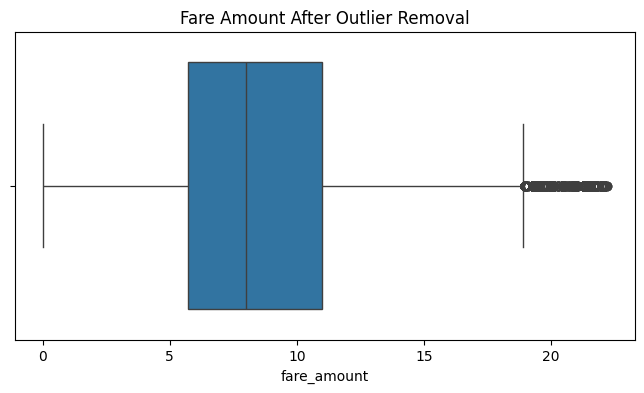

In [13]:
# Filter NYC geographical coordinates
df = df[
    df['pickup_latitude'].between(40.0, 42.0) &
    df['dropoff_latitude'].between(40.0, 42.0) &
    df['pickup_longitude'].between(-75.0, -72.0) &
    df['dropoff_longitude'].between(-75.0, -72.0)
]

# Remove zero and extreme distances
df = df[
    (df['distance_km'] > 0) &
    (df['distance_km'] <= 100)
]

# IQR method for fare outliers
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

df = df[df['fare_amount'].between(lower, upper)]

print("Lower Bound:", lower)
print("Upper Bound:", upper)

print("Shape after outlier removal:", df.shape)

# Boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])

plt.title("Fare Amount After Outlier Removal")
plt.show()

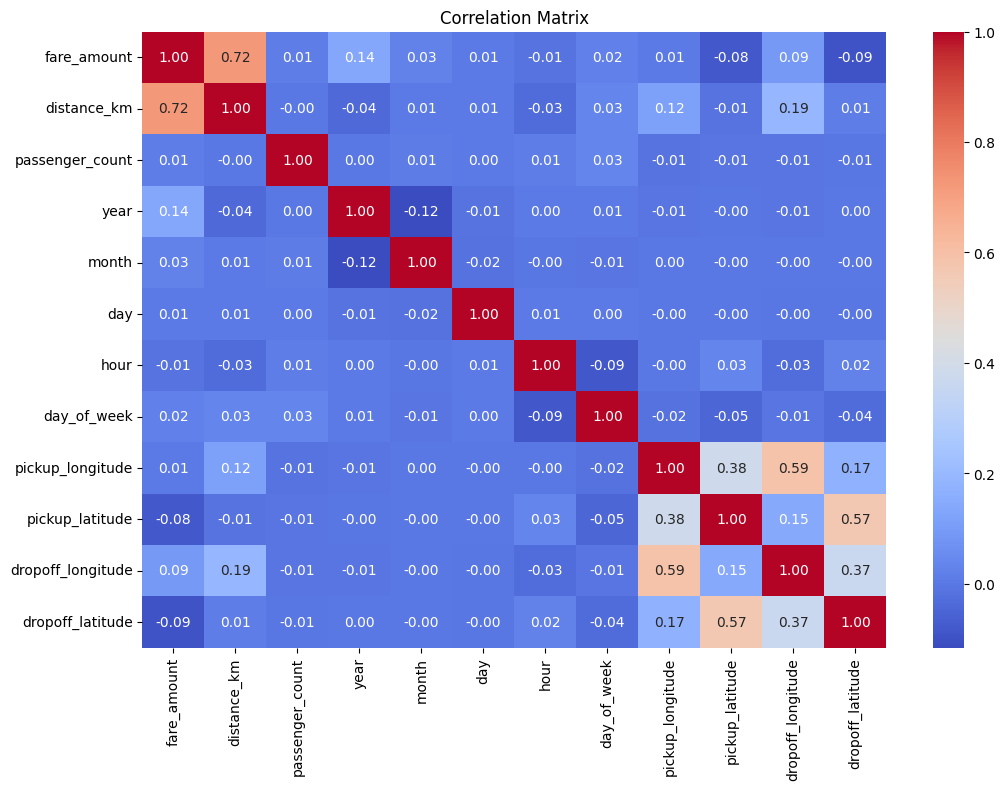

In [14]:
corr_cols = [
    'fare_amount',
    'distance_km',
    'passenger_count',
    'year',
    'month',
    'day',
    'hour',
    'day_of_week',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
]

corr = df[corr_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

In [15]:
features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'year',
    'month',
    'day',
    'hour',
    'day_of_week',
    'distance_km'
]

X = df[features]
y = df['fare_amount']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 141235
Testing Samples: 35309


In [16]:
# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression model
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

# Prediction
linear_pred = linear_model.predict(X_test_scaled)

# Evaluation
linear_r2 = r2_score(y_test, linear_pred)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_pred)
)

linear_mae = mean_absolute_error(
    y_test, linear_pred
)

print("Linear Regression Results")

print("R2 Score:", linear_r2)
print("RMSE:", linear_rmse)
print("MAE:", linear_mae)

Linear Regression Results
R2 Score: 0.5446288090967637
RMSE: 2.7930732768995212
MAE: 1.766786169513321


In [17]:
# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Prediction
rf_pred = rf_model.predict(X_test)

# Evaluation
rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_mae = mean_absolute_error(
    y_test, rf_pred
)

print("Random Forest Regression Results")

print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)

Random Forest Regression Results
R2 Score: 0.787696075064123
RMSE: 1.9071223928053558
MAE: 1.3166572666386058


In [18]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],

    'R2': [linear_r2, rf_r2],

    'RMSE': [linear_rmse, rf_rmse],

    'MAE': [linear_mae, rf_mae]
})

display(results)

,Model,R2,RMSE,MAE
0,Linear Regression,0.544629,2.793073,1.766786
1,Random Forest Regression,0.787696,1.907122,1.316657


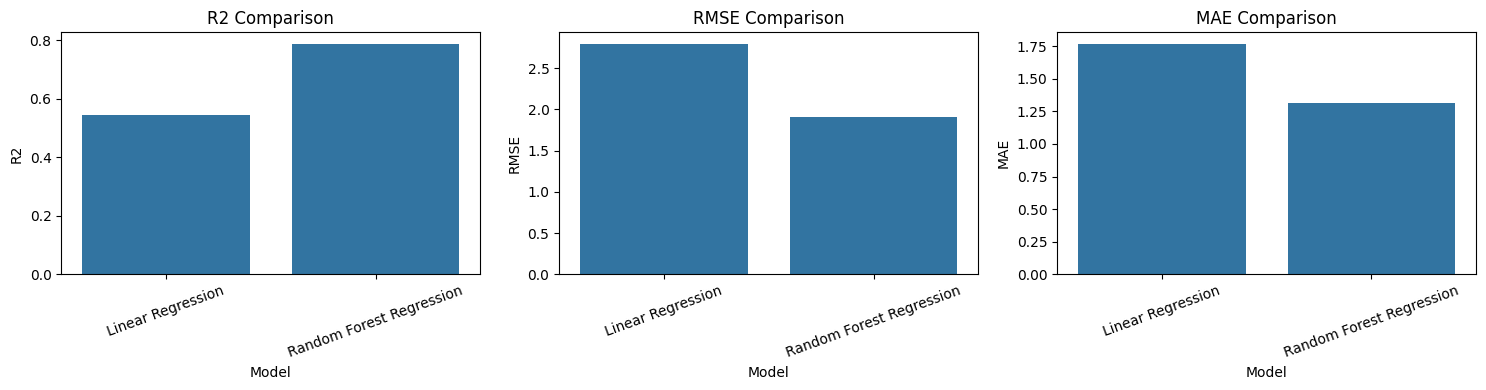

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=results, x='Model', y='R2', ax=axes[0])
axes[0].set_title('R2 Comparison')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=results, x='Model', y='RMSE', ax=axes[1])
axes[1].set_title('RMSE Comparison')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=results, x='Model', y='MAE', ax=axes[2])
axes[2].set_title('MAE Comparison')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

,Feature,Importance
10,distance_km,0.760686
5,year,0.044404
3,dropoff_latitude,0.035767
2,dropoff_longitude,0.031058
0,pickup_longitude,0.028537
8,hour,0.025429
1,pickup_latitude,0.025400
7,day,0.015829
6,month,0.015515
9,day_of_week,0.012567


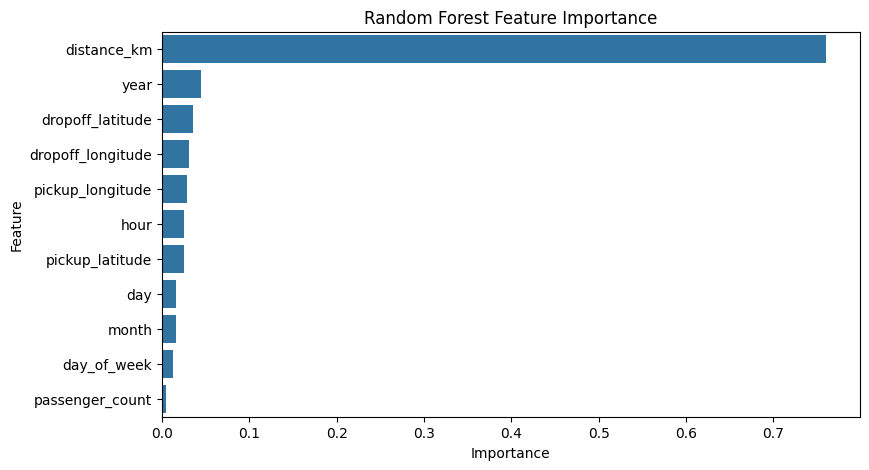

In [20]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.show()

In [21]:
# New ride details
new_ride = pd.DataFrame({
    'pickup_longitude': [-73.985],
    'pickup_latitude': [40.748],
    'dropoff_longitude': [-73.985],
    'dropoff_latitude': [40.758],
    'passenger_count': [1],
    'year': [2015],
    'month': [6],
    'day': [15],
    'hour': [18],
    'day_of_week': [0],
    'distance_km': [1.2]
})

# Linear Regression prediction
new_ride_scaled = scaler.transform(new_ride)

linear_fare = linear_model.predict(
    new_ride_scaled
)[0]

# Random Forest prediction
rf_fare = rf_model.predict(new_ride)[0]

print(
    "Predicted fare using Linear Regression: $",
    round(linear_fare, 2)
)

print(
    "Predicted fare using Random Forest: $",
    round(rf_fare, 2)
)

Predicted fare using Linear Regression: $ 8.13
Predicted fare using Random Forest: $ 8.21
